#### Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

print(f"✅ Imports listos")
print(f"TensorFlow: {tf.__version__}")

✅ Imports listos
TensorFlow: 2.21.0


#### Set-Up

In [ ]:
IMAGE_DIR  = r"D:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\Dataset\Occidente_Copy\Dataset_Adjusted" #<-- Your Path to the image directory
IMG_HEIGHT = 256    # height  ← formato rectangular 
IMG_WIDTH  = 128    # width  ← formato rectangular
LATENT_DIM = 512   # between 64 and 512
BATCH_SIZE = 8
EPOCHS     = 200
LR         = 1e-3

# Validar LATENT_DIM
# assert 64 <= LATENT_DIM <= 256, "❌ LATENT_DIM should be between 64 and 256"
assert 64 <= LATENT_DIM <= 512, "❌ LATENT_DIM should be between 64 and 512"


print(f"Tamaño de imagen: {IMG_HEIGHT}x{IMG_WIDTH} (height x width)")
print(f"Dimensión latente: {LATENT_DIM}")
print(f"IMAGE_DIR existe: {os.path.exists(IMAGE_DIR)}")

Tamaño de imagen: 256x128 (alto x ancho)
Dimensión latente: 512
IMAGE_DIR existe: True


#### Images


In [ ]:
#Function to load color images
def cargar_imagenes_color(image_dir, img_height, img_width):
    """
    Carga imágenes a color (RGB) sin convertir a escala de grises.
    Retorna array (N, img_height, img_width, 3) normalizado en [0, 1].
    """
    VALID_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}
    imagenes  = []
    rutas     = []
    errores   = []

    archivos = sorted([f for f in os.listdir(image_dir)
                       if os.path.splitext(f)[1].lower() in VALID_EXT])

    print(f"Archivos encontrados: {len(archivos)}")

    for nombre in archivos:
        ruta = os.path.join(image_dir, nombre)
        try:
            img = Image.open(ruta)

            
            if img.mode == 'RGBA':
                fondo = Image.new('RGB', img.size, (127, 127, 127))
                fondo.paste(img, mask=img.split()[3])
                img = fondo
            elif img.mode == 'CMYK':
                img = img.convert('RGB')
            elif img.mode == 'L':
                img = img.convert('RGB')
            elif img.mode != 'RGB':
                img = img.convert('RGB')

            img       = img.resize((img_width, img_height))
            img_array = np.array(img, dtype='float32') / 255.0  # normalizar [0,1]

            imagenes.append(img_array)
            rutas.append(ruta)

        except Exception as e:
            errores.append(nombre)
            print(f"  ⚠ Error en {nombre}: {e}")

    X = np.array(imagenes)  # (N, img_size, img_size, 3)

    print(f"\n✅ Imágenes cargadas correctamente: {len(imagenes)}")
    if errores:
        print(f"⚠  Imágenes con error: {errores}")
    print(f"Shape del dataset: {X.shape}")
    print(f"Rango de valores:  [{X.min():.2f}, {X.max():.2f}]")

    return X, rutas

X, rutas = cargar_imagenes_color(IMAGE_DIR, IMG_HEIGHT, IMG_WIDTH)


Archivos encontrados: 58

✅ Imágenes cargadas correctamente: 58
Shape del dataset: (58, 256, 128, 3)
Rango de valores:  [0.02, 1.00]


#### Verify

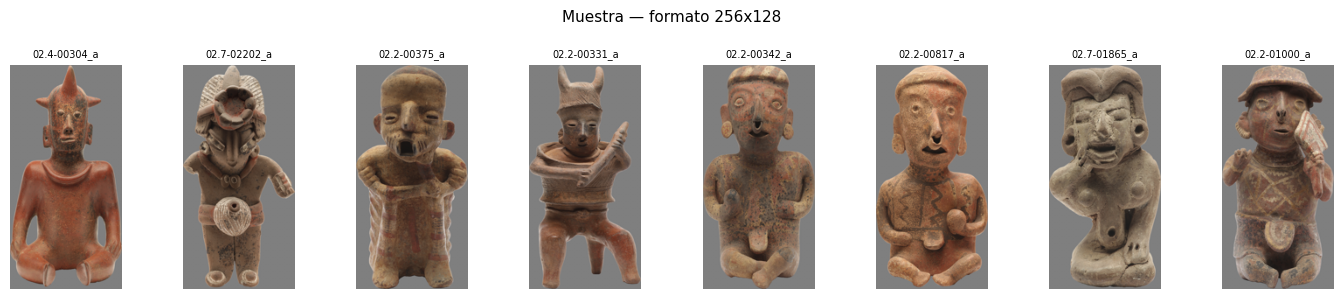

In [ ]:
#Function to visualize a sample of images
def ver_muestra(X, rutas, n=8):
    n       = min(n, len(X))
    indices = np.random.choice(len(X), n, replace=False)
    fig, axes = plt.subplots(1, n, figsize=(14, 3))

    for ax, idx in zip(axes, indices):
        ax.imshow(X[idx])
        ax.set_title(os.path.basename(rutas[idx])[:12], fontsize=7)
        ax.axis('off')

    plt.suptitle(f'Muestra — formato {IMG_HEIGHT}x{IMG_WIDTH}', fontsize=11)
    plt.tight_layout()
    plt.savefig('muestra_dataset.png', dpi=150)
    plt.show()

ver_muestra(X, rutas)

#### Autoencoder


In [ ]:
#Function to build a convolutional autoencoder with adjustable latent dimension
def build_convolutional_autoencoder(img_height=256, img_width=128, latent_dim=128):

    assert 64 <= latent_dim <= 512, "❌ LATENT_DIM debe estar entre 64 y 512"

    # ── Encoder ─────────────────────────────────────────────
    inputs = keras.Input(shape=(img_height, img_width, 3), name='encoder_input')

    # Bloque 1: (256,128,3) → (128,64,64)  ← empieza en 64 no 32
    x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D((2,2), padding='same')(x)

    # Bloque 2: (128,64,64) → (64,32,128)
    x = layers.Conv2D(128, (3,3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2,2), padding='same')(x)

    # Bloque 3: (64,32,128) → (32,16,256)
    x = layers.Conv2D(256, (3,3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2,2), padding='same')(x)

    # Bloque 4: (32,16,256) → (16,8,512)
    x = layers.Conv2D(512, (3,3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2,2), padding='same')(x)

    # Bloque 5: (16,8,512) → (8,4,512)
    #x = layers.Conv2D(512, (3,3), activation='relu', padding='same')(x)
    #x = layers.MaxPooling2D((2,2), padding='same')(x)

    # Espacio latente
    shape_antes_flatten = x.shape[1:]              # (8, 4, 512)
    x       = layers.Flatten()(x)
    latente = layers.Dense(latent_dim, activation='relu', name='latente')(x)

    encoder = keras.Model(inputs, latente, name='encoder')

    # ── Decoder ─────────────────────────────────────────────
    decoder_input = keras.Input(shape=(latent_dim,), name='decoder_input')

    x = layers.Dense(np.prod(shape_antes_flatten), activation='relu')(decoder_input)
    x = layers.Reshape(shape_antes_flatten)(x)              # (8,4,512)

    # Bloque 1: (8,4,512) → (16,8,512)
    # x = layers.UpSampling2D((2,2), interpolation='bilinear')(x)
    # x = layers.Conv2D(512, (3,3), activation='relu', padding='same')(x)
    # x = layers.Conv2D(512, (3,3), activation='relu', padding='same')(x)

    # Bloque 2: (16,8,512) → (32,16,256)
    x = layers.UpSampling2D((2,2), interpolation='bilinear')(x)
    x = layers.Conv2D(256, (3,3), activation='relu', padding='same')(x)
    x = layers.Conv2D(256, (3,3), activation='relu', padding='same')(x)

    # Bloque 3: (32,16,256) → (64,32,128)
    x = layers.UpSampling2D((2,2), interpolation='bilinear')(x)
    x = layers.Conv2D(128, (3,3), activation='relu', padding='same')(x)
    x = layers.Conv2D(128, (3,3), activation='relu', padding='same')(x)

    # Bloque 4: (64,32,128) → (128,64,64)
    x = layers.UpSampling2D((2,2), interpolation='bilinear')(x)
    x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)
    x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)

    # Bloque 5: (128,64,64) → (256,128,3)
    x = layers.UpSampling2D((2,2), interpolation='bilinear')(x)
    x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)
    decoded = layers.Conv2D(3, (3,3), activation='sigmoid',
                            padding='same', name='decoder_output')(x)

    decoder = keras.Model(decoder_input, decoded, name='decoder')

    # ── Autoencoder completo ─────────────────────────────────
    autoencoder_output = decoder(encoder(inputs))
    autoencoder = keras.Model(inputs, autoencoder_output, name='autoencoder')

    return autoencoder, encoder, decoder


# Construir
autoencoder, encoder, decoder = build_convolutional_autoencoder(
    img_height=IMG_HEIGHT,
    img_width=IMG_WIDTH,
    latent_dim=LATENT_DIM
)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR),
    loss='mse'
)

encoder.summary()
print(f"\nParámetros totales: {autoencoder.count_params():,}")

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 256, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 256, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 128, 64, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 128, 64, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 64, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 64, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 8, 512)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latente (Dense)                 │ (None, 128)            │     8,388,736 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,939,712 (37.92 MB)

 Trainable params: 9,939,712 (37.92 MB)

 Non-trainable params: 0 (0.00 B)


Parámetros totales: 20,755,843


#### Training


In [ ]:
#Training the autoencoder
callbacks = [
    EarlyStopping(
        monitor='loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        'autoencoder_mejor.keras',
        monitor='loss',
        save_best_only=True,
        verbose=0
    )
]

print("Iniciando entrenamiento...")
print(f"  Imágenes:   {X.shape[0]}")
print(f"  IMG_SIZE:   {IMG_SIZE}")
print(f"  BATCH_SIZE: {BATCH_SIZE}")
print(f"  EPOCHS:     {EPOCHS}")
print(f"  LATENT_DIM: {LATENT_DIM}\n")

history = autoencoder.fit(
    X, X,                    # entrada = salida esperada
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

print("\n✅ Entrenamiento finalizado")
print(f"Mejor loss: {min(history.history['loss']):.6f}")
print(f"Épocas entrenadas: {len(history.history['loss'])}")

Iniciando entrenamiento...
  Imágenes:   58


NameError: name 'IMG_SIZE' is not defined

In [18]:
callbacks = [
    EarlyStopping(
        monitor='loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        'autoencoder_mejor.keras',
        monitor='loss',
        save_best_only=True,
        verbose=0
    )
]

print("Iniciando entrenamiento...")
print(f"  Imágenes:      {X.shape[0]}")
print(f"  Formato:       {IMG_HEIGHT}x{IMG_WIDTH}")
print(f"  LATENT_DIM:    {LATENT_DIM}")
print(f"  BATCH_SIZE:    {BATCH_SIZE}")
print(f"  EPOCHS máx:    {EPOCHS}\n")

history = autoencoder.fit(
    X, X,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

print(f"\n✅ Entrenamiento finalizado")
print(f"Mejor loss:        {min(history.history['loss']):.6f}")
print(f"Épocas entrenadas: {len(history.history['loss'])}")

Iniciando entrenamiento...
  Imágenes:      58
  Formato:       256x128
  LATENT_DIM:    128
  BATCH_SIZE:    8
  EPOCHS máx:    200

Epoch 1/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - loss: 0.0057
Epoch 2/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - loss: 0.0056
Epoch 3/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - loss: 0.0056
Epoch 4/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - loss: 0.0056
Epoch 5/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - loss: 0.0055
Epoch 6/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - loss: 0.0055
Epoch 7/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - loss: 0.0062
Epoch 8/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - loss: 0.0073
Epoch 9/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - loss: 0.0078
Epoch 10/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - loss: 0.0071
Epoch 11/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - loss: 0.0072
Epoch 12/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - loss: 0.0070
Epoch 13/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - loss: 0.0066
Epoch 14/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1

#### Evaluation

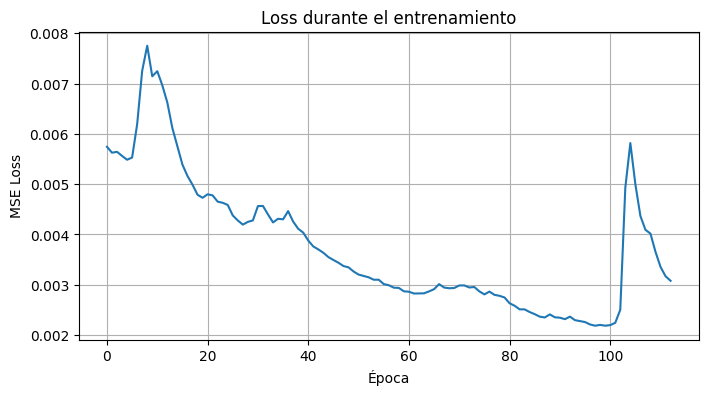

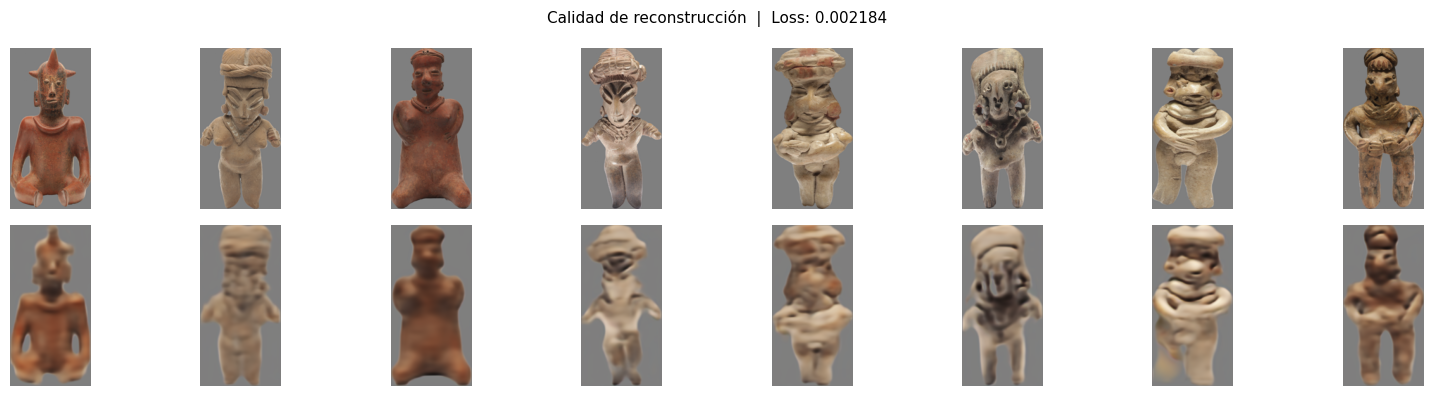

In [19]:
# Curva de loss
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'])
plt.title('Loss durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.savefig('loss_curve.png', dpi=150)
plt.show()

# Originales vs reconstruidas
n             = min(8, len(X))
indices       = np.random.choice(len(X), n, replace=False)
muestra       = X[indices]
reconstruidas = autoencoder.predict(muestra, verbose=0)

fig, axes = plt.subplots(2, n, figsize=(16, 4))
for i in range(n):
    axes[0, i].imshow(muestra[i])
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_ylabel('Original', fontweight='bold', fontsize=9)

    axes[1, i].imshow(reconstruidas[i])
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_ylabel('Reconstruida', fontweight='bold', fontsize=9)

plt.suptitle(f'Calidad de reconstrucción  |  Loss: {min(history.history["loss"]):.6f}',
             fontsize=11)
plt.tight_layout()
plt.savefig('reconstrucciones.png', dpi=150)
plt.show()

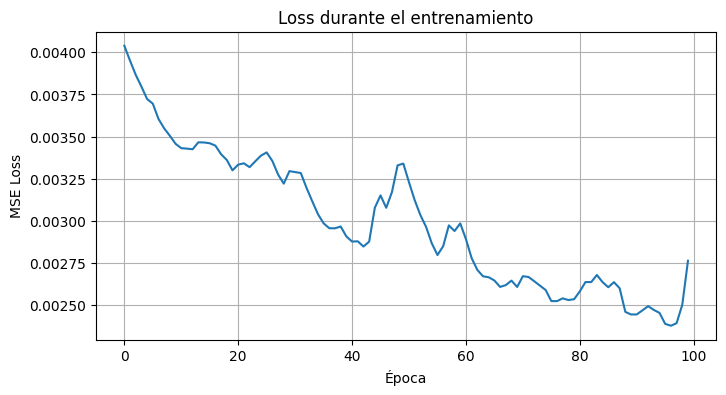

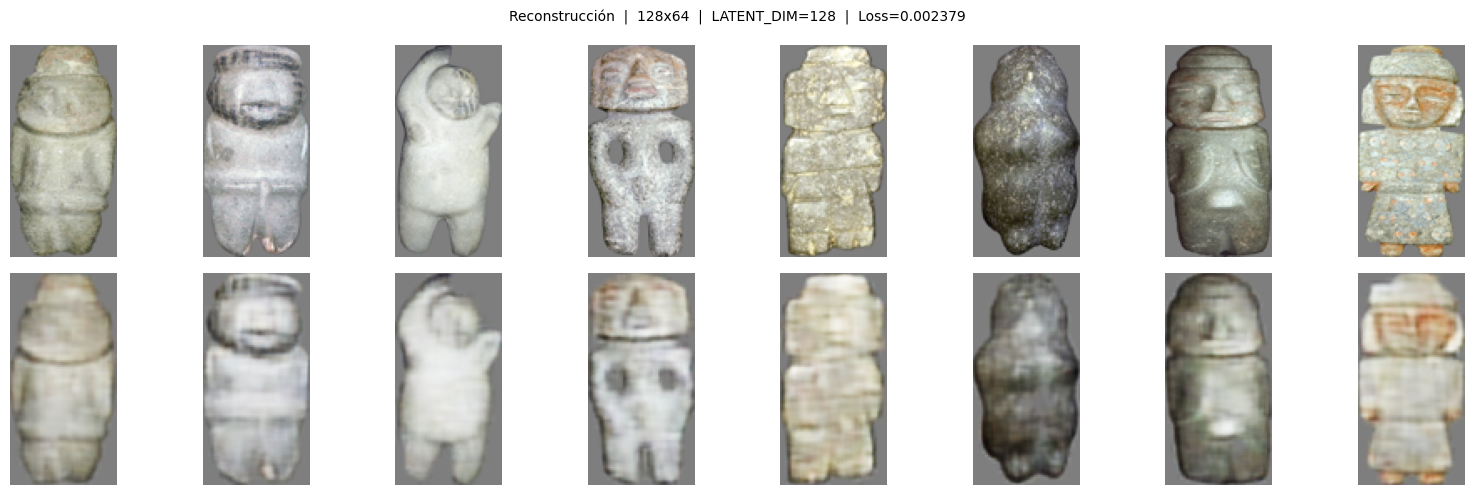

In [24]:
# Curva de loss
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'])
plt.title('Loss durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.savefig('loss_curve.png', dpi=150)
plt.show()

# Originales vs reconstruidas
n             = min(8, len(X))
indices       = np.random.choice(len(X), n, replace=False)
muestra       = X[indices]
reconstruidas = autoencoder.predict(muestra, verbose=0)

fig, axes = plt.subplots(2, n, figsize=(16, 5))
for i in range(n):
    axes[0, i].imshow(muestra[i])
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_ylabel('Original', fontweight='bold', fontsize=9)

    axes[1, i].imshow(reconstruidas[i])
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_ylabel('Reconstruida', fontweight='bold', fontsize=9)

plt.suptitle(f'Reconstrucción  |  {IMG_HEIGHT}x{IMG_WIDTH}  |  '
             f'LATENT_DIM={LATENT_DIM}  |  '
             f'Loss={min(history.history["loss"]):.6f}', fontsize=10)
plt.tight_layout()
plt.savefig('reconstrucciones.png', dpi=150)
plt.show()

#### Features_Extractor

In [8]:
# Extraer vectores con el encoder ya entrenado
print("Extrayendo features con encoder entrenado...")
features_array = encoder.predict(X, verbose=1)  # (137, 128)

print(f"\n✅ Features extraídas: {features_array.shape}")
print(f"   Una fila por imagen:    {features_array.shape[0]}")
print(f"   Dimensiones del vector: {features_array.shape[1]}")

# Verificar calidad
print(f"\nEstadísticas:")
print(f"  Media:   {features_array.mean():.4f}")
print(f"  Std:     {features_array.std():.4f}")
print(f"  Min:     {features_array.min():.4f}")
print(f"  Max:     {features_array.max():.4f}")
print(f"  NaN:     {np.isnan(features_array).sum()}")

# Guardar CSV
nombres  = [os.path.basename(r) for r in rutas]
columnas = [f'z_{i}' for i in range(features_array.shape[1])]

df = pd.DataFrame(features_array, columns=columnas)
df.insert(0, 'archivo', nombres)

df.to_csv('features_encoder.csv', index=False, encoding='utf-8-sig')

print(f"\n💾 Guardado: features_encoder.csv")
print(f"   {df.shape[0]} filas  x  {df.shape[1]} columnas")
print(f"\nPreview:")
print(df.iloc[:5, :6])

Extrayendo features con encoder entrenado...
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step

✅ Features extraídas: (133, 128)
   Una fila por imagen:    133
   Dimensiones del vector: 128

Estadísticas:
  Media:   -0.3942
  Std:     25.1233
  Min:     -167.5258
  Max:     129.8193
  NaN:     0

💾 Guardado: features_encoder.csv
   133 filas  x  129 columnas

Preview:
                   archivo        z_0        z_1        z_2        z_3  \
0       0000_10_253159.png  15.617587 -14.203155 -20.672808   8.047033   
1  0006_043_0001 copia.png -26.312971  -3.560571  51.821507  11.854916   
2  0009_003_0001 copia.png  17.577492 -40.679436  -0.818630  61.870228   
3       0011_049 copia.png  12.372274  15.643231   7.726189  -6.340881   
4  0011_050_0001 copia.png  -6.745870 -11.496757 -23.158281  20.091671   

         z_4  
0 -17.444450  
1  20.510859  
2 -20.744637  
3 -19.928869  
4   8.520596  


In [20]:
print("Extrayendo features...")
features_array = encoder.predict(X, verbose=1)  # (N, LATENT_DIM)

print(f"\n✅ Features extraídas: {features_array.shape}")
print(f"   Imágenes:   {features_array.shape[0]}")
print(f"   Dimensiones: {features_array.shape[1]}")
print(f"\nEstadísticas:")
print(f"  Media:  {features_array.mean():.4f}")
print(f"  Std:    {features_array.std():.4f}")
print(f"  Min:    {features_array.min():.4f}")
print(f"  Max:    {features_array.max():.4f}")
print(f"  NaN:    {np.isnan(features_array).sum()}")

# Guardar CSV
nombres  = [os.path.basename(r) for r in rutas]
columnas = [f'z_{i}' for i in range(features_array.shape[1])]

df = pd.DataFrame(features_array, columns=columnas)
df.insert(0, 'archivo', nombres)
df.to_csv('features_encoder_occidente_V1.csv', index=False, encoding='utf-8-sig')

print(f"\n💾 features_encoder_occidente_V1.csv guardado")
print(f"   {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"\nPreview:")
print(df.iloc[:5, :6])

Extrayendo features...
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 293ms/step

✅ Features extraídas: (58, 128)
   Imágenes:   58
   Dimensiones: 128

Estadísticas:
  Media:  0.0476
  Std:    0.3340
  Min:    0.0000
  Max:    7.8115
  NaN:    0

💾 features_encoder_occidente_V1.csv guardado
   58 filas x 129 columnas

Preview:
             archivo  z_0  z_1  z_2  z_3  z_4
0   02.2-00331_a.png  0.0  0.0  0.0  0.0  0.0
1   02.2-00332_a.png  0.0  0.0  0.0  0.0  0.0
2   02.2-00334_a.png  0.0  0.0  0.0  0.0  0.0
3  02.2-00340_aB.png  0.0  0.0  0.0  0.0  0.0
4   02.2-00341_a.png  0.0  0.0  0.0  0.0  0.0


In [ ]:
#Save the autoencoder and encoder models
autoencoder.save('autoencoder_final_Occidente_V1.keras')
encoder.save('encoder_final_Occidente_V1.keras')

print("💾 autoencoder_final_Occidente_V1.keras")
print("💾 encoder_final_Occidente_V1.keras")

💾 autoencoder_final_Occidente_V1.keras
💾 encoder_final_Occidente_V1.keras
